# 07 · The 3-qubit bit-flip repetition code

**The classical idea:** send `0` as `000`. If one bit flips you get `010`, and a majority vote recovers `0`.

**The quantum problem:** we can't copy $|\psi\rangle$ (no cloning), and we can't measure the data
qubits to take a vote without destroying the superposition.

**The quantum fix:**
1. **Encode** with CNOTs: $\alpha|0\rangle+\beta|1\rangle \to \alpha|000\rangle+\beta|111\rangle$.
   That's entanglement, not three copies.
2. **Syndrome measurement:** use two *ancilla* qubits to measure only the **parities**
   $Z_0Z_1$ ("do q0 and q1 agree?") and $Z_1Z_2$. Both branches $|000\rangle$ and $|111\rangle$
   give the *same* parity answers, so the measurement reveals **where** the error is but nothing about
   $\alpha, \beta$, and the superposition survives.
3. **Correct** with a conditional `X`, then **decode** by undoing the CNOTs.

| syndrome (anc1 anc0) | meaning | fix |
|---|---|---|
| `00` | no error | none |
| `01` | q0 disagrees | X on q0 |
| `11` | q1 disagrees with both neighbours | X on q1 |
| `10` | q2 disagrees | X on q2 |

**Limits:** it corrects any **single** bit flip but fails with two, and it does nothing about **phase** flips.
Shor's 9-qubit code and surface codes handle both.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

sim = AerSimulator()
SHOTS = 4096
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed series order: blue, orange, aqua

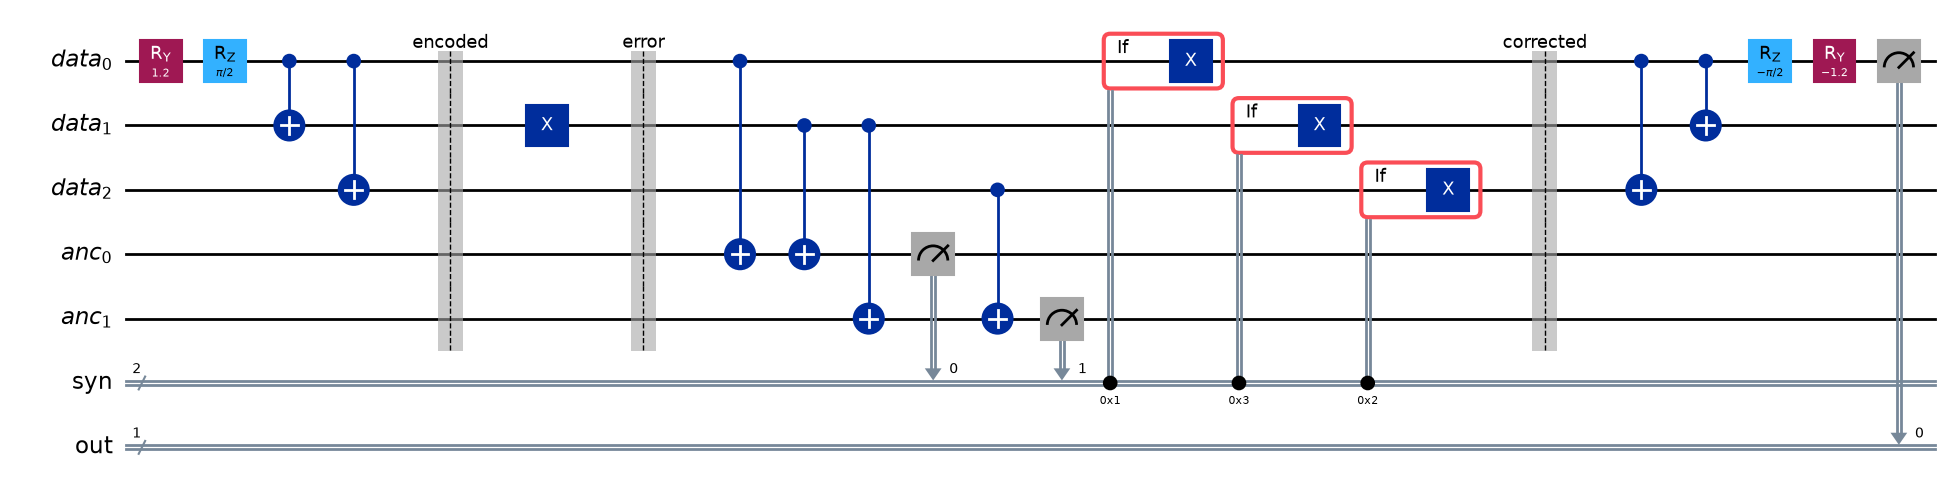

In [2]:
def bit_flip_code(theta=1.2, phi=np.pi / 2, errors=(), correct=True, noisy_channel=False):
    """Encode RZ(phi) RY(theta)|0>, apply errors, detect + correct, decode, verify.

    errors        : data-qubit indices to hit with a deliberate X (bit flip)
    noisy_channel : add an 'id' gate on each data qubit; a noise model can turn it into a random flip
    """
    data = QuantumRegister(3, "data")
    anc = QuantumRegister(2, "anc")
    syn = ClassicalRegister(2, "syn")   # syn[0] = parity(q0,q1), syn[1] = parity(q1,q2)
    out = ClassicalRegister(1, "out")
    qc = QuantumCircuit(data, anc, syn, out)

    # Logical state |psi> ~ cos(theta/2)|0> + e^{i phi} sin(theta/2)|1> on data[0].
    # phi = pi/2 makes X|psi> orthogonal to |psi>, so any uncorrected flip fails the final check.
    qc.ry(theta, data[0])
    qc.rz(phi, data[0])

    # ENCODE: spread the basis value of q0 onto q1 and q2 -> alpha|000> + beta|111>
    qc.cx(data[0], data[1])
    qc.cx(data[0], data[2])
    qc.barrier(label="encoded")

    # ERROR: the "noisy channel"
    for q in errors:
        qc.x(data[q])                   # deliberate bit flip
    if noisy_channel:
        qc.id(data)                     # placeholders where the noise model inserts random flips
    qc.barrier(label="error")

    # SYNDROME: copy pairwise parities into the ancillas (never measuring the data directly)
    qc.cx(data[0], anc[0]); qc.cx(data[1], anc[0])   # anc0 = q0 XOR q1
    qc.cx(data[1], anc[1]); qc.cx(data[2], anc[1])   # anc1 = q1 XOR q2
    qc.measure(anc, syn)

    # CORRECT: classical feed-forward from the syndrome (integer value = syn[1]*2 + syn[0])
    if correct:
        with qc.if_test((syn, 0b01)):
            qc.x(data[0])
        with qc.if_test((syn, 0b11)):
            qc.x(data[1])
        with qc.if_test((syn, 0b10)):
            qc.x(data[2])
    qc.barrier(label="corrected")

    # DECODE: undo the encoding -> data[0] holds |psi>, data[1], data[2] back to |0>
    qc.cx(data[0], data[2])
    qc.cx(data[0], data[1])

    # VERIFY: undo the preparation. If |psi> survived, data[0] is |0> on every shot.
    qc.rz(-phi, data[0])
    qc.ry(-theta, data[0])
    qc.measure(data[0], out)
    return qc

bit_flip_code(errors=[1]).draw("mpl", fold=-1)

In [3]:
def analyse(counts):
    """Keys look like 'out syn'. Returns (syndromes seen, fraction where the logical qubit survived)."""
    syndromes, ok = {}, 0
    for key, c in counts.items():
        out, syn = key.split()
        syndromes[syn] = syndromes.get(syn, 0) + c
        ok += c if out == "0" else 0
    return syndromes, ok / sum(counts.values())

print(f"{'error on':<12}{'syndrome':<12}{'with correction':<18}{'without correction'}")
for errs in [(), (0,), (1,), (2,)]:
    syn, ok = analyse(sim.run(transpile(bit_flip_code(errors=errs), sim), shots=SHOTS).result().get_counts())
    _, ok_nc = analyse(sim.run(transpile(bit_flip_code(errors=errs, correct=False), sim), shots=SHOTS).result().get_counts())
    label = f"data[{errs[0]}]" if errs else "none"
    print(f"{label:<12}{'/'.join(syn):<12}{ok:<18.1%}{ok_nc:.1%}")

error on    syndrome    with correction   without correction


none        00          100.0%            100.0%
data[0]     01          100.0%            0.0%


data[1]     11          100.0%            100.0%
data[2]     10          100.0%            100.0%


**Reading the table:**
* Each single error produces one **deterministic** syndrome, and correction brings the state back 100% of the time.
* The syndrome never depends on $\theta$, so it carries no information about the logical state.
* Without correction, a flip on `data[0]` corrupts the decoded qubit. Flips on `data[1]`/`data[2]` happen not to
  reach `data[0]` with this decoder, but if they're left uncorrected they pile up, and one more flip would then be fatal.

### Two errors defeat the code
With two flips the majority is wrong. The syndrome points at the one qubit that's still correct,
and the "correction" completes a **logical** error ($|000\rangle \leftrightarrow |111\rangle$):

In [4]:
syn, ok = analyse(sim.run(transpile(bit_flip_code(errors=(0, 1)), sim), shots=SHOTS).result().get_counts())
print(f"errors on data[0] and data[1]: syndrome {list(syn)} -> logical qubit survived {ok:.1%}")

errors on data[0] and data[1]: syndrome ['10'] -> logical qubit survived 0.0%


## Random noise: when does the code help?
Now each data qubit flips **independently with probability $p$** (an Aer noise model on the `id` gates).
* Unprotected qubit: fails with probability $p$.
* Encoded qubit: fails only if ≥ 2 of 3 flip, $p_L = 3p^2 - 2p^3$.

The code helps whenever $p_L < p$, which is true for every $p < 0.5$. Near $p \approx 0$ the gain is dramatic
($p_L \approx 3p^2$). This is a toy version of the **threshold** idea behind fault-tolerant quantum computing.
(Here encoding, syndrome extraction and correction are perfect. On real hardware those steps are noisy too.)

We use the logical state $|1\rangle$ ($\theta=\pi$) so that a single bit flip is always a real error.

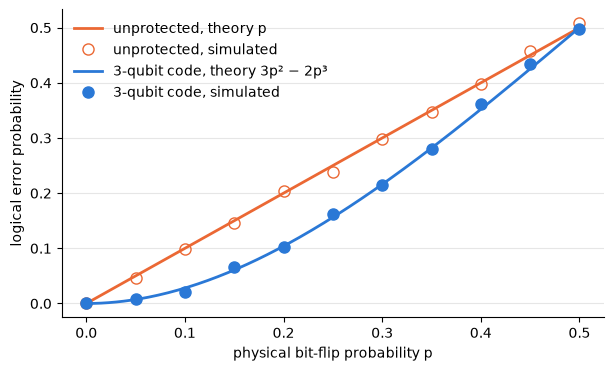

In [5]:
def noisy_sim(p):
    flip = pauli_error([("X", p), ("I", 1 - p)])
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(flip, ["id"])   # only the 'id' gates of the channel are noisy
    return AerSimulator(noise_model=nm)

def unprotected(theta=np.pi):
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0); qc.id(0); qc.ry(-theta, 0); qc.measure(0, 0)
    return qc

ps = np.linspace(0, 0.5, 11)
fail_code, fail_bare = [], []
for p in ps:
    s = noisy_sim(p)
    # optimization_level=0 keeps the 'id' gates (higher levels would delete them as no-ops)
    c = s.run(transpile(bit_flip_code(theta=np.pi, noisy_channel=True), s, optimization_level=0), shots=SHOTS).result().get_counts()
    fail_code.append(1 - analyse(c)[1])
    c = s.run(transpile(unprotected(), s, optimization_level=0), shots=SHOTS).result().get_counts()
    fail_bare.append(c.get("1", 0) / SHOTS)

pf = np.linspace(0, 0.5, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pf, pf, color=COLORS[1], lw=2, label="unprotected, theory p")
ax.plot(ps, fail_bare, "o", color=COLORS[1], ms=8, mfc="none", label="unprotected, simulated")
ax.plot(pf, 3 * pf**2 - 2 * pf**3, color=COLORS[0], lw=2, label="3-qubit code, theory 3p² − 2p³")
ax.plot(ps, fail_code, "o", color=COLORS[0], ms=8, label="3-qubit code, simulated")
ax.set(xlabel="physical bit-flip probability p", ylabel="logical error probability")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="0.9")
ax.legend(frameon=False)
plt.show()